# Baselines, LightGBM y modelos propios en PyTorch 

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import common as C
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
pd.set_option("display.width", 200)
panel = C.load_panel()
MAIN = ["naive", "snaive_24h", "snaive_168h", "mstl", "lightgbm_global", "mlp", "dlinear", "nlinear"]
res = {m: C.evaluate(C.PRED_DIR / f"{m}.parquet", panel) for m in MAIN}
resumen = pd.read_csv(C.RESUMEN_PATH).set_index("modelo")

## 1. Resultados en prueba (2014-10-01 a 2014-12-31, 92 orígenes × 24 h × 100 clientes)

In [2]:
tab = pd.DataFrame({m: {**r["global"], "MASE_22_28dic": r["xmas"]["MASE"]} for m, r in res.items()}).T
tab = tab.drop(columns="MAPE_n_excluidos").join(resumen[["params_totales", "t_entrenamiento_s", "t_inferencia_s"]])
display(tab.sort_values("MASE").round(4))

,MAE,RMSE,WAPE,MAPE,MASE,MASE_22_28dic,params_totales,t_entrenamiento_s,t_inferencia_s
lightgbm_global,33.9263,164.6167,0.0629,0.1031,0.8499,1.5421,126000.0,188.5,3.1
mlp,37.4969,175.6836,0.0695,0.1107,0.8927,1.6360,533528.0,177.2,4.5
dlinear,37.5763,184.7384,0.0697,0.1107,0.9165,2.0230,16176.0,26.4,2.3
nlinear,37.6243,184.6919,0.0698,0.1108,0.9280,1.9949,8088.0,15.0,2.1
mstl,38.8977,193.0826,0.0721,0.1111,0.9521,2.1792,0.0,0.0,1245.3
snaive_24h,45.8698,236.3032,0.0850,0.1397,1.0875,2.4717,0.0,0.0,0.9
snaive_168h,43.1660,192.4684,0.0800,0.1109,1.1494,1.6672,0.0,0.0,0.9
naive,174.4063,531.8018,0.3234,0.3915,4.2734,4.3498,0.0,0.0,0.9


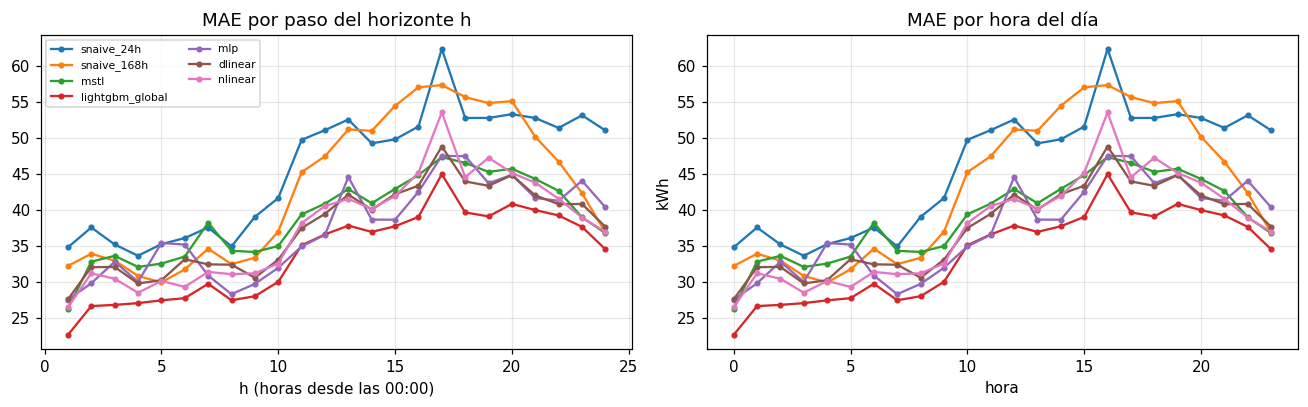

      naive  snaive_24h  snaive_168h   mstl  lightgbm_global    mlp  dlinear  nlinear
h=1   1.763       0.862        0.895  0.606            0.572  0.606    0.584    0.569
h=6   3.171       0.745        0.828  0.755            0.642  0.733    0.733    0.651
h=12  5.373       1.312        1.322  1.074            0.973  0.952    1.058    1.084
h=18  5.896       1.329        1.482  1.175            1.033  1.154    1.127    1.144
h=24  1.015       1.015        0.967  0.848            0.803  0.873    0.848    0.831


In [3]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for m in MAIN[1:]:
    axs[0].plot(res[m]["by_h"].index, res[m]["by_h"]["MAE"], "o-", ms=3, label=m)
    axs[1].plot(res[m]["by_hour"].index, res[m]["by_hour"]["MAE"], "o-", ms=3, label=m)
axs[0].set_title("MAE por paso del horizonte h"); axs[0].set_xlabel("h (horas desde las 00:00)"); axs[0].legend(fontsize=7, ncol=2)
axs[1].set_title("MAE por hora del día"); axs[1].set_xlabel("hora"); axs[1].set_ylabel("kWh")
plt.tight_layout(); plt.savefig("figs/mae_h_hora_A.png"); plt.show()
print(pd.DataFrame({m: res[m]["by_h"]["MASE"].iloc[[0, 5, 11, 17, 23]].values for m in MAIN}, index=["h=1", "h=6", "h=12", "h=18", "h=24"]).round(3))

## 2. LightGBM: selección de hiperparámetros (solo validación)

In [4]:
display(pd.read_csv("results/lgbm_grid.csv").round(4))

,config,objective,num_leaves,mejor_iter,val_MAE_norm,t_s,min_child_samples
0,l1_h63,l1,63,2000,0.1965,209.8,NaN
1,l2_h127,l2,127,1618,0.1975,214.6,50.0
2,l2_h63,l2,63,1750,0.1984,154.1,NaN
3,l2_h31,l2,31,2000,0.1996,105.1,NaN


## 3. MLP, DLinear y NLinear: iteraciones sobre validación (L = 48, 168, 336)

,modelo,L,params_totales,params_entrenables,mejor_epoca,epocas_corridas,val_MAE,val_MASE,t_total_s,t_epoca_s,mem_gpu_MB
0,mlp,48,386072,386072,21,25,35.275,0.868,361.339,14.454,1132.141
1,mlp,168,447512,447512,8,12,32.229,0.799,192.269,16.022,1158.984
2,mlp,336,533528,533528,9,13,32.023,0.795,223.321,17.179,1192.688
3,dlinear,48,2352,2352,4,8,37.002,0.912,45.410,5.676,1192.688
4,dlinear,168,8112,8112,4,8,33.094,0.835,50.717,6.340,1192.688
5,dlinear,336,16176,16176,3,7,32.631,0.824,54.434,7.776,1192.688
6,nlinear,48,1176,1176,4,8,36.972,0.912,25.596,3.199,1192.688
7,nlinear,168,4056,4056,4,8,33.015,0.833,35.718,4.465,1192.688
8,nlinear,336,8088,8088,2,6,32.584,0.822,32.272,5.379,1192.688


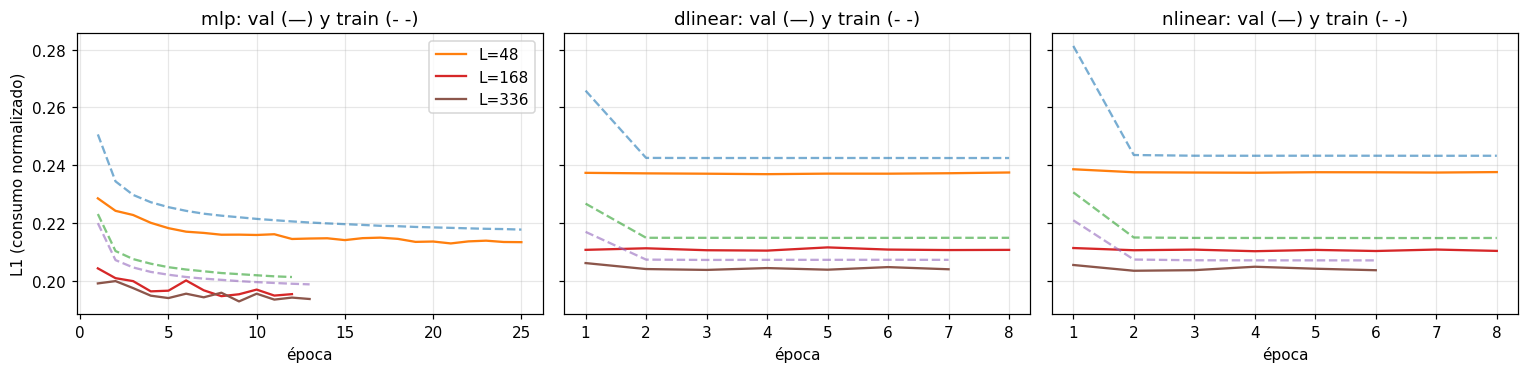

In [5]:
it = pd.read_csv("results/iteraciones_A.csv"); sm = pd.read_csv("results/iteraciones_A_resumen.csv")
display(sm.drop(columns=["val_loss"]).round(3))
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, (name, g) in zip(axs, it.groupby("modelo", sort=False)):
    for L, h in g.groupby("L"):
        ax.plot(h.epoca, h.train_loss, "--", alpha=.6); ax.plot(h.epoca, h.val_loss, "-", label=f"L={L}")
    ax.set_title(f"{name}: val (—) y train (- -)"); ax.set_xlabel("época")
axs[0].set_ylabel("L1 (consumo normalizado)"); axs[0].legend()
plt.tight_layout(); plt.savefig("figs/curvas_perdida_A.png"); plt.show()

## 4. Efecto de los meses de historia (3, 12 y 30 meses antes del 2014-09-30)

modelo,dlinear,lightgbm_global,mlp,nlinear
meses,,,,
3,0.9151,1.0049,1.4134,0.9084
12,0.9041,0.8530,0.8488,0.9029
30,0.9225,0.8511,0.8572,0.9116
33,0.9165,0.8499,0.8927,0.9280


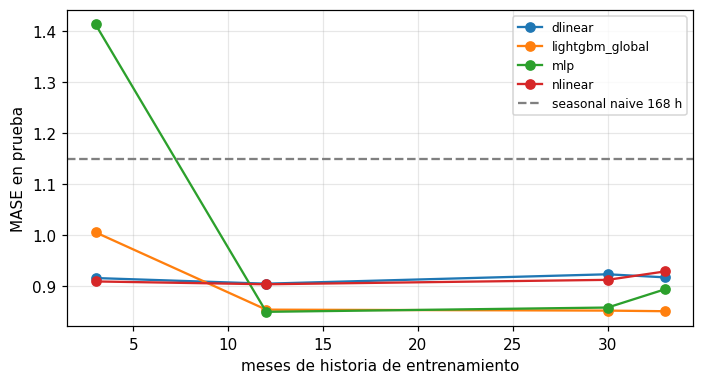

In [6]:
hist = []
for fam in ["lightgbm_global", "mlp", "dlinear", "nlinear"]:
    for months, tag in [(3, "_hist03m"), (12, "_hist12m"), (30, "_hist30m"), (33, "")]:
        r = C.evaluate(C.PRED_DIR / f"{fam}{tag}.parquet", panel)
        hist.append({"modelo": fam, "meses": months, "MASE": r["global"]["MASE"], "WAPE": r["global"]["WAPE"]})
hist = pd.DataFrame(hist); hist.to_csv("results/historia_A.csv", index=False)
display(hist.pivot(index="meses", columns="modelo", values="MASE").round(4))
fig, ax = plt.subplots(figsize=(6.5, 3.6))
for fam, g in hist.groupby("modelo"): ax.plot(g.meses, g.MASE, "o-", label=fam)
ax.axhline(res["snaive_168h"]["global"]["MASE"], c="gray", ls="--", label="seasonal naive 168 h")
ax.set_xlabel("meses de historia de entrenamiento"); ax.set_ylabel("MASE en prueba"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("figs/mase_vs_historia_A.png"); plt.show()

In [7]:
print(resumen.loc[MAIN, ["familia", "L_horas", "estrategia", "covariables", "params_totales", "t_entrenamiento_s", "t_epoca_s", "t_inferencia_s", "mem_gpu_MB", "hardware"]].to_string())

                  familia               L_horas                       estrategia      covariables  params_totales  t_entrenamiento_s  t_epoca_s  t_inferencia_s  mem_gpu_MB            hardware
modelo                                                                                                                                                                                         
naive            Baseline                1344.0       local, reajuste por origen               no             0.0                0.0        NaN             0.9         NaN            Apple M5
snaive_24h       Baseline                1344.0       local, reajuste por origen               no             0.0                0.0        NaN             0.9         NaN            Apple M5
snaive_168h      Baseline                1344.0       local, reajuste por origen               no             0.0                0.0        NaN             0.9         NaN            Apple M5
mstl             Baseline               